In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import STL

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Загрузка датасета, проверка и подготовка временного ряда

In [109]:
import kagglehub
import os
dataset_path = kagglehub.dataset_download("berkeleyearth/climate-change-earth-surface-temperature-data")
csv_path = os.path.join(dataset_path, "GlobalLandTemperaturesByCountry.csv")

df = pd.read_csv(csv_path)
print("Размер датасета:", df.shape)
df.head()

Using Colab cache for faster access to the 'climate-change-earth-surface-temperature-data' dataset.
Размер датасета: (577462, 4)


,dt,AverageTemperature,AverageTemperatureUncertainty,Country
0,1743-11-01,4.384,2.294,Åland
1,1743-12-01,NaN,NaN,Åland
2,1744-01-01,NaN,NaN,Åland
3,1744-02-01,NaN,NaN,Åland
4,1744-03-01,NaN,NaN,Åland


In [110]:
#посмотрим какие страны есть в датасете
countries = sorted(df["Country"].dropna().unique())
print(f"Всего стран в датасете: {len(countries)}")
print()
n_cols = 8
for i in range(0, len(countries), n_cols):
    chunk = countries[i:i + n_cols]
    print("  ".join(f"{c:<28s}" for c in chunk))

Всего стран в датасете: 243

Afghanistan                   Africa                        Albania                       Algeria                       American Samoa                Andorra                       Angola                        Anguilla                    
Antarctica                    Antigua And Barbuda           Argentina                     Armenia                       Aruba                         Asia                          Australia                     Austria                     
Azerbaijan                    Bahamas                       Bahrain                       Baker Island                  Bangladesh                    Barbados                      Belarus                       Belgium                     
Belize                        Benin                         Bhutan                        Bolivia                       Bonaire, Saint Eustatius And Saba  Bosnia And Herzegovina        Botswana                      Brazil                      
British Vi

In [111]:
#выбираем страны и проверим количество записей

COUNTRY = "New Zealand"
data = df[df["Country"] == COUNTRY].copy()
print(f"Записей для {COUNTRY}: {len(data)}")

#переводим в формат даты
data["dt"] = pd.to_datetime(data["dt"])
data = data.set_index("dt").sort_index()

#задаем целевую переменную (средняя температура)
ts = data["AverageTemperature"]

print(f"Период: {ts.index.min().date()} — {ts.index.max().date()}")
print(f"Пропусков: {ts.isna().sum()}")

Записей для New Zealand: 1929
Период: 1853-01-01 — 2013-09-01
Пропусков: 1


In [112]:
#обработаем пропуск через линейную интерполяцию
ts = ts.interpolate(method="linear", limit_direction="both")
print(f"Пропусков после интерполяции: {ts.isna().sum()}")

Пропусков после интерполяции: 0


In [113]:
#проверяем частоты ряда
try:
    inferred = pd.infer_freq(ts.index)
    print(f"Автоопределение pandas (pd.infer_freq): {inferred}")
except ValueError:
    print("Автоопределение pandas: не удалось (нерегулярный шаг или пропуски)")

Автоопределение pandas (pd.infer_freq): MS


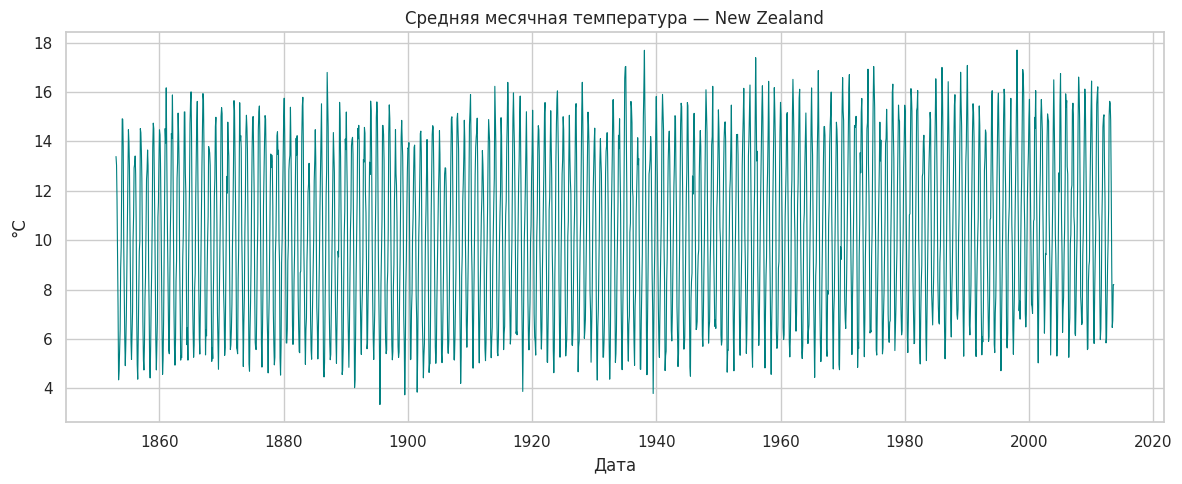

In [114]:
#базовый график временного ряда
plt.plot(ts, color="teal", linewidth=0.8)
plt.title(f"Средняя месячная температура — {COUNTRY}")
plt.ylabel("°C")
plt.xlabel("Дата")
plt.tight_layout()
plt.show()

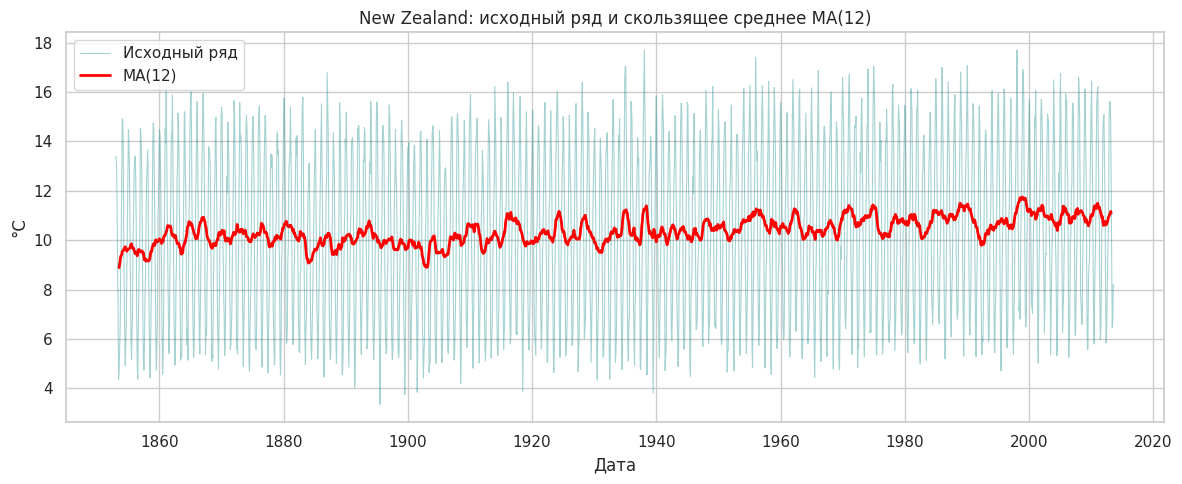

Доля дисперсии компонент, %:
trend        2.1
seasonal    94.8
resid        3.1
dtype: float64


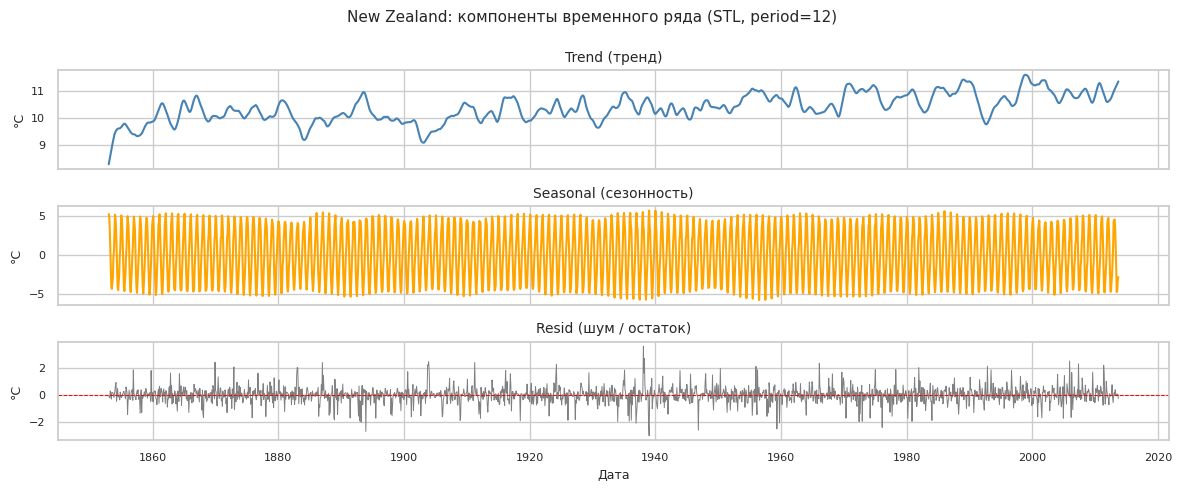

In [115]:
#STL график, скользящее среднее
SEASON_PERIOD = 12

#Скользящее среднее MA(12)
roll_12 = ts.rolling(window=12, center=True).mean()
plt.plot(ts.index, ts.values, color="teal", linewidth=0.8, alpha=0.35, label="Исходный ряд")
plt.plot(roll_12.index, roll_12.values, color="red", linewidth=2, label="MA(12)")
plt.title(f"{COUNTRY}: исходный ряд и скользящее среднее MA(12)")
plt.xlabel("Дата")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()

#STL декомпозиция
stl = STL(ts, period=SEASON_PERIOD, robust=True)
res = stl.fit()
trend    = res.trend
seasonal = res.seasonal
resid    = res.resid

components = pd.DataFrame({
    "trend":    trend,
    "seasonal": seasonal,
    "resid":    resid})
var_total = components.var()
var_share = (var_total / var_total.sum() * 100).round(1)
print("Доля дисперсии компонент, %:")
print(var_share)
fig, axes = plt.subplots(3, 1, sharex=True)

axes[0].plot(components.index, components["trend"], color="steelblue")
axes[0].set_title("Trend (тренд)", fontsize=10)
axes[0].set_ylabel("°C", fontsize=9)
axes[1].plot(components.index, components["seasonal"], color="orange")
axes[1].set_title("Seasonal (сезонность)", fontsize=10)
axes[1].set_ylabel("°C", fontsize=9)
axes[2].plot(components.index, components["resid"], color="gray", linewidth=0.7)
axes[2].axhline(0, color="red", linestyle="--", linewidth=0.7)
axes[2].set_title("Resid (шум / остаток)", fontsize=10)
axes[2].set_ylabel("°C", fontsize=9)
axes[2].set_xlabel("Дата", fontsize=9)
for ax in axes:
    ax.tick_params(axis="both", labelsize=8)

plt.suptitle(f"{COUNTRY}: компоненты временного ряда (STL, period=12)", fontsize=11)
plt.tight_layout()
plt.show()

Получили временной ряд из 1929 точек для Новой Зеландии, состоящий из наблюдений на начало каждого месяца, пропуски обработаны интерполяцией. Код частоты MS pandas (Month Start) подтердил, что шаг регулярный и совпадает с календарем месяцев. На графике видна сезонность (пики и провалы на графике), заметен небольшой тренд на увеличение температуры за последнее столетие

## 2. Проверки корреляции и генерация признаков

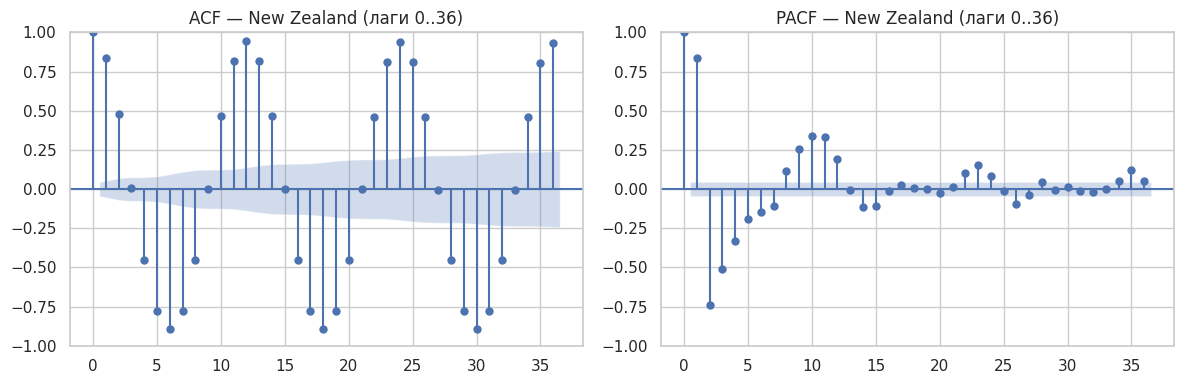

ACF на ключевых лагах:
  lag  1: +0.837
  lag  2: +0.478
  lag 12: +0.947
  lag 24: +0.939

PACF на ключевых лагах:
  lag  1: +0.837
  lag  2: -0.741
  lag 12: +0.189
  lag 24: +0.081


In [116]:
#првоеряем ACF/PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ts, lags=36, ax=axes[0])
axes[0].set_title(f"ACF — {COUNTRY} (лаги 0..36)")
plot_pacf(ts, lags=36, ax=axes[1], method="ywm")
axes[1].set_title(f"PACF — {COUNTRY} (лаги 0..36)")
plt.tight_layout()
plt.show()

acf_vals  = acf(ts, nlags=24, fft=False)
pacf_vals = pacf(ts, nlags=24, method="ywm")
print("ACF на ключевых лагах:")
for lag in [1, 2, 12, 24]:
    print(f"  lag {lag:>2}: {acf_vals[lag]:+.3f}")
print("\nPACF на ключевых лагах:")
for lag in [1, 2, 12, 24]:
    print(f"  lag {lag:>2}: {pacf_vals[lag]:+.3f}")

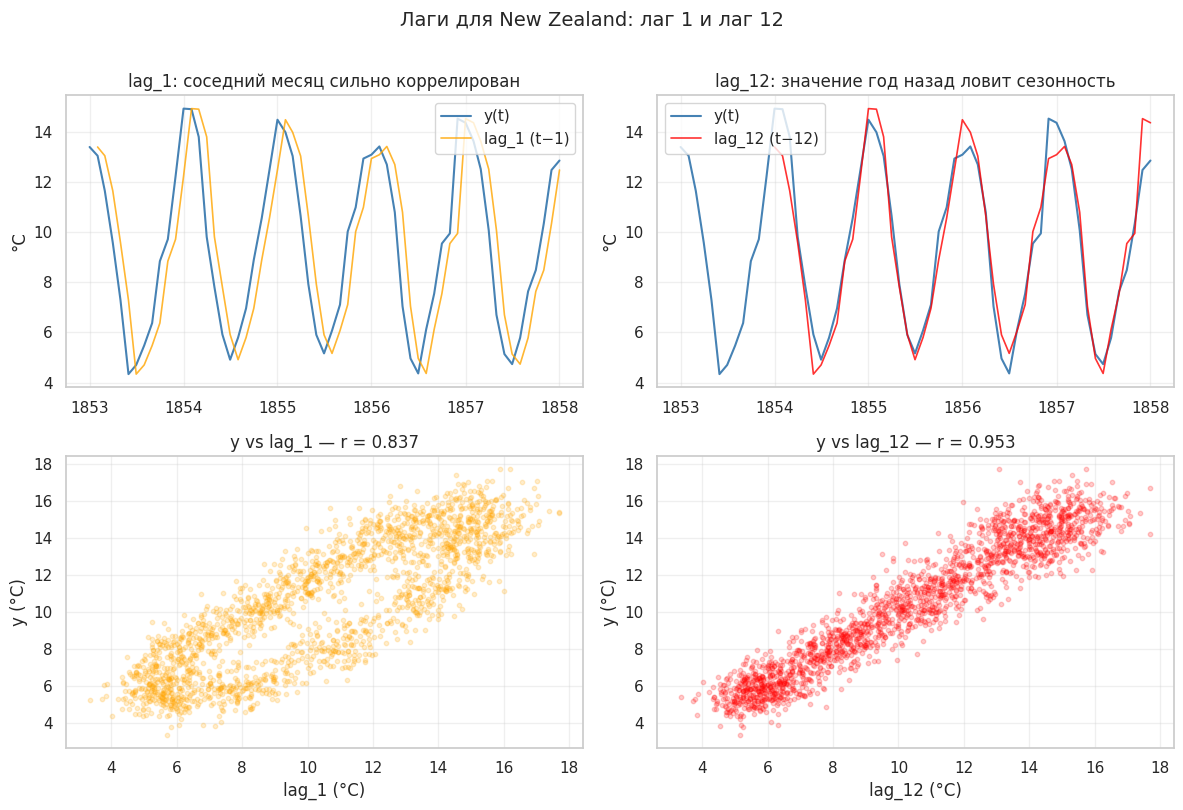

In [117]:
#Визуализация лагов
lag_1_series  = ts.shift(1)
lag_12_series = ts.shift(12)
lag_1_pairs  = pd.concat([lag_1_series,  ts], axis=1, keys=["lag_1",  "y"]).dropna()
lag_12_pairs = pd.concat([lag_12_series, ts], axis=1, keys=["lag_12", "y"]).dropna()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
zoom_end = ts.index[0] + pd.DateOffset(years=5)

axes[0, 0].plot(ts.loc[:zoom_end].index, ts.loc[:zoom_end].values,
                color="steelblue", linewidth=1.5, label="y(t)")
axes[0, 0].plot(lag_1_series.loc[:zoom_end].index, lag_1_series.loc[:zoom_end].values,
                color="orange", linewidth=1.2, alpha=0.8, label="lag_1 (t−1)")
axes[0, 0].set_title("lag_1: соседний месяц сильно коррелирован", fontsize=12)
axes[0, 0].set_ylabel("°C")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 1].plot(ts.loc[:zoom_end].index, ts.loc[:zoom_end].values,
                color="steelblue", linewidth=1.5, label="y(t)")
axes[0, 1].plot(lag_12_series.loc[:zoom_end].index, lag_12_series.loc[:zoom_end].values,
                color="red", linewidth=1.2, alpha=0.8, label="lag_12 (t−12)")
axes[0, 1].set_title("lag_12: значение год назад ловит сезонность", fontsize=12)
axes[0, 1].set_ylabel("°C")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].scatter(lag_1_pairs["lag_1"], lag_1_pairs["y"], alpha=0.2, s=10, color="orange")
axes[1, 0].set_xlabel("lag_1 (°C)")
axes[1, 0].set_ylabel("y (°C)")
r1 = lag_1_pairs["lag_1"].corr(lag_1_pairs["y"])
axes[1, 0].set_title(f"y vs lag_1 — r = {r1:.3f}", fontsize=12)
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].scatter(lag_12_pairs["lag_12"], lag_12_pairs["y"], alpha=0.2, s=10, color="red")
axes[1, 1].set_xlabel("lag_12 (°C)")
axes[1, 1].set_ylabel("y (°C)")
r12 = lag_12_pairs["lag_12"].corr(lag_12_pairs["y"])
axes[1, 1].set_title(f"y vs lag_12 — r = {r12:.3f}", fontsize=12)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(f"Лаги для {COUNTRY}: лаг 1 и лаг 12", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

График ACF показывает пики на лагах кратных 12 (12, 24, 36) и провалы на лагах полугодий (6, 18, 30), значения очень медленно затухают: ACF на лаг12 не сильно отличается ACF на лаг 24. Это говорит о ярко выраженной годовой сезонности, которая повторяется из года в год. PACF доминирует на лаге 1, т.е. предыдущий месяц сильно похож на текущий. Лаг 2 автоматически уходит вниз при сильной корреляции лаг 1, лаг 2 не берем в модель. Значимый по PACF лаг 12 выше доверительной полосы (0.19) и будет добавлен в модель как показыающий сигнал. Точки выстраиваются в диагональ на лаг 1 и аг 12 с целевой переменной, что говорит данные сильной положительной автокорреляции.

In [118]:
#генерируем признаки
#feature matrix для месячного температурного ряда
fm = pd.DataFrame({"y": ts})

#Лаги (1 и 12)
for lag in [1, 12]:
    fm[f"lag_{lag}"] = ts.shift(lag)

#Rolling. Окна 3 и 12 (квартал и год)
for w in [3, 12]:
    fm[f"roll_mean_{w}"] = ts.rolling(window=w).mean()
    fm[f"roll_std_{w}"]  = ts.rolling(window=w).std()

#Expanding (куммулятивные данные)
fm["expanding_mean"] = ts.expanding(min_periods=12).mean()
fm["expanding_std"]  = ts.expanding(min_periods=12).std()

#Признаки даты
fm["month"]      = ts.index.month
fm["quarter"]    = ts.index.quarter

#Признаки сезонности
monthly_avg = ts.groupby(ts.index.month).mean()
cold_months = tuple(sorted(monthly_avg.nsmallest(3).index.tolist()))
fm["is_cold_season"] = fm["month"].isin(cold_months).astype(int)
fm["month_sin"]  = np.sin(2 * np.pi * fm["month"] / 12)
fm["month_cos"]  = np.cos(2 * np.pi * fm["month"] / 12)
print(f"Холодные месяцы: {cold_months}")
print(f"Средняя t зимой: {ts[ts.index.month.isin(cold_months)].mean():.2f} °C")
print(f"Средняя t летом:  {ts[~ts.index.month.isin(cold_months)].mean():.2f} °C")

#Разности год к году
fm["diff_1"]  = ts.diff(1)
fm["diff_12"] = ts.diff(12)

#Целевой признак: прогноз на следующий месяц
fm["y_target"] = ts.shift(-1)
fm = fm.dropna()
FEATURE_COLS = [c for c in fm.columns if c not in ("y", "y_target")]

print(f"\nFeature matrix: {fm.shape[0]} строк × {fm.shape[1]} столбцов")
print(f"Признаки: {list(fm.columns)}")
fm.head()

Холодные месяцы: (6, 7, 8)
Средняя t зимой: 5.92 °C
Средняя t летом:  11.85 °C

Feature matrix: 1916 строк × 17 столбцов
Признаки: ['y', 'lag_1', 'lag_12', 'roll_mean_3', 'roll_std_3', 'roll_mean_12', 'roll_std_12', 'expanding_mean', 'expanding_std', 'month', 'quarter', 'is_cold_season', 'month_sin', 'month_cos', 'diff_1', 'diff_12', 'y_target']


,y,lag_1,lag_12,roll_mean_3,roll_std_3,roll_mean_12,roll_std_12,expanding_mean,expanding_std,month,quarter,is_cold_season,month_sin,month_cos,diff_1,diff_12,y_target
dt,,,,,,,,,,,,,,,,,
1854-01-01,14.916,12.220,13.387,12.283000,2.602072,9.011667,3.462418,9.348231,3.530141,1,1,0,0.500000,8.660254e-01,2.696,1.529,14.893
1854-02-01,14.893,14.916,13.039,14.009667,1.549939,9.166167,3.692203,9.744286,3.701259,2,1,0,0.866025,5.000000e-01,-0.023,1.854,13.790
1854-03-01,13.790,14.893,11.643,14.533000,0.643560,9.345083,3.870835,10.014000,3.716448,3,1,0,1.000000,6.123234e-17,-1.103,2.147,9.808
1854-04-01,9.808,13.790,9.577,12.830333,2.674888,9.364333,3.872667,10.001125,3.590799,4,2,0,0.866025,-5.000000e-01,-3.982,0.231,7.810
1854-05-01,7.810,9.808,7.286,10.469333,3.044359,9.408000,3.849990,9.872235,3.517156,5,2,0,0.500000,-8.660254e-01,-1.998,0.524,5.920


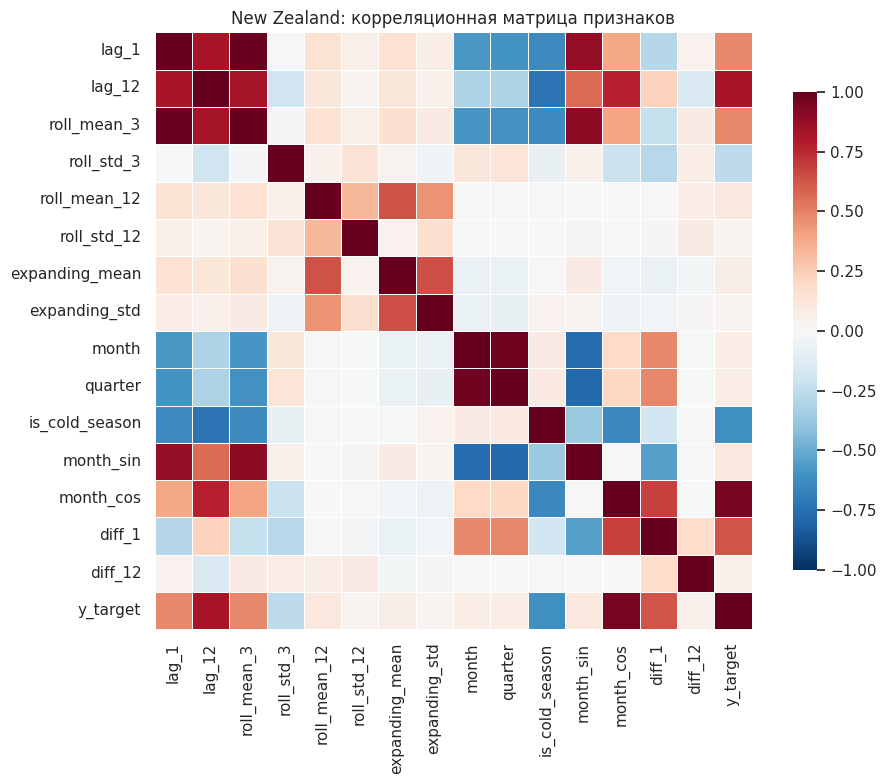

In [119]:
corr_matrix = fm[FEATURE_COLS + ["y_target"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.8})
plt.title(f"{COUNTRY}: корреляционная матрица признаков")
plt.tight_layout()
plt.show()

Наблюдаем мульколлинеарность, оставим только признаки из каждой группы по одному. Не будем брать в модель колонки: roll_mean_3, quarter, month, expanding_mean. Также убираем roll_std_3, roll_std_12, expanding_std, diff_12, diff_1 из-за низкой связи с целевой переменной

In [120]:
FINAL_COLS = [
    "lag_1",
    "lag_12",
    "roll_mean_12",
    "month_sin",
    "month_cos",
    "is_cold_season"]

In [121]:
#формируем финальный датафрейм
missing = [c for c in FINAL_COLS if c not in fm.columns]
assert not missing, f"В fm нет колонок: {missing}"
fm_final = fm[FINAL_COLS + ["y_target"]].copy()

print(f"Финальный датафрейм: {fm_final.shape[0]} строк × {fm_final.shape[1]} столбцов")
print(f"Признаки ({len(FINAL_COLS)}): {FINAL_COLS}")
print(f"Пропусков: {fm_final.isna().sum().sum()}")
display(fm_final.head())

Финальный датафрейм: 1916 строк × 7 столбцов
Признаки (6): ['lag_1', 'lag_12', 'roll_mean_12', 'month_sin', 'month_cos', 'is_cold_season']
Пропусков: 0


,lag_1,lag_12,roll_mean_12,month_sin,month_cos,is_cold_season,y_target
dt,,,,,,,
1854-01-01,12.220,13.387,9.011667,0.500000,8.660254e-01,0,14.893
1854-02-01,14.916,13.039,9.166167,0.866025,5.000000e-01,0,13.790
1854-03-01,14.893,11.643,9.345083,1.000000,6.123234e-17,0,9.808
1854-04-01,13.790,9.577,9.364333,0.866025,-5.000000e-01,0,7.810
1854-05-01,9.808,7.286,9.408000,0.500000,-8.660254e-01,0,5.920


## 3. Holdout-разбиение

Train: 1532 строк (1854-01-01 — 1981-08-01)
Test:  384 строк (1981-09-01 — 2013-08-01)
Граница: train заканчивается 1981-08-01, test начинается 1981-09-01


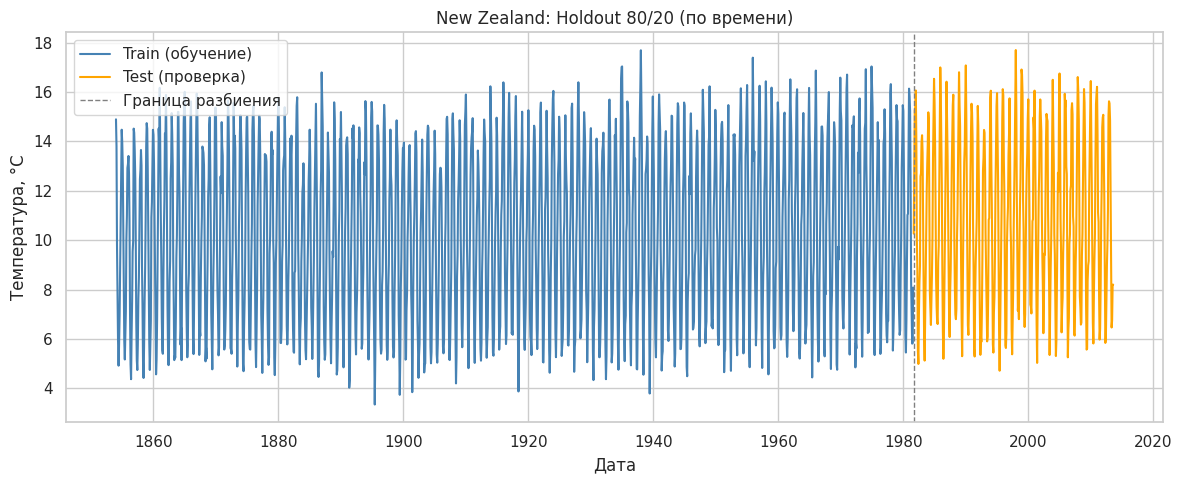

In [122]:
train_size = int(len(fm_final) * 0.8)
train = fm_final.iloc[:train_size].copy()
test  = fm_final.iloc[train_size:].copy()

X_train, y_train = train[FINAL_COLS], train["y_target"]
X_test,  y_test  = test[FINAL_COLS],  test["y_target"]

print(f"Train: {len(train)} строк ({train.index.min().date()} — {train.index.max().date()})")
print(f"Test:  {len(test)} строк ({test.index.min().date()} — {test.index.max().date()})")
print(f"Граница: train заканчивается {train.index.max().date()}, test начинается {test.index.min().date()}")

plt.plot(train.index, train["y_target"], label="Train (обучение)", color="steelblue")
plt.plot(test.index, test["y_target"], label="Test (проверка)", color="orange")
plt.axvline(test.index[0], color="gray", linestyle="--", linewidth=1, label="Граница разбиения")
plt.title(f"{COUNTRY}: Holdout 80/20 (по времени)")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Скользящее окно

Всего сгенерировано сплитов: 149
Первый: train 1854-01-01 — 1863-12-01 | test 1864-01-01 — 1864-12-01
Последний: train 2002-01-01 — 2011-12-01 | test 2012-01-01 — 2012-12-01




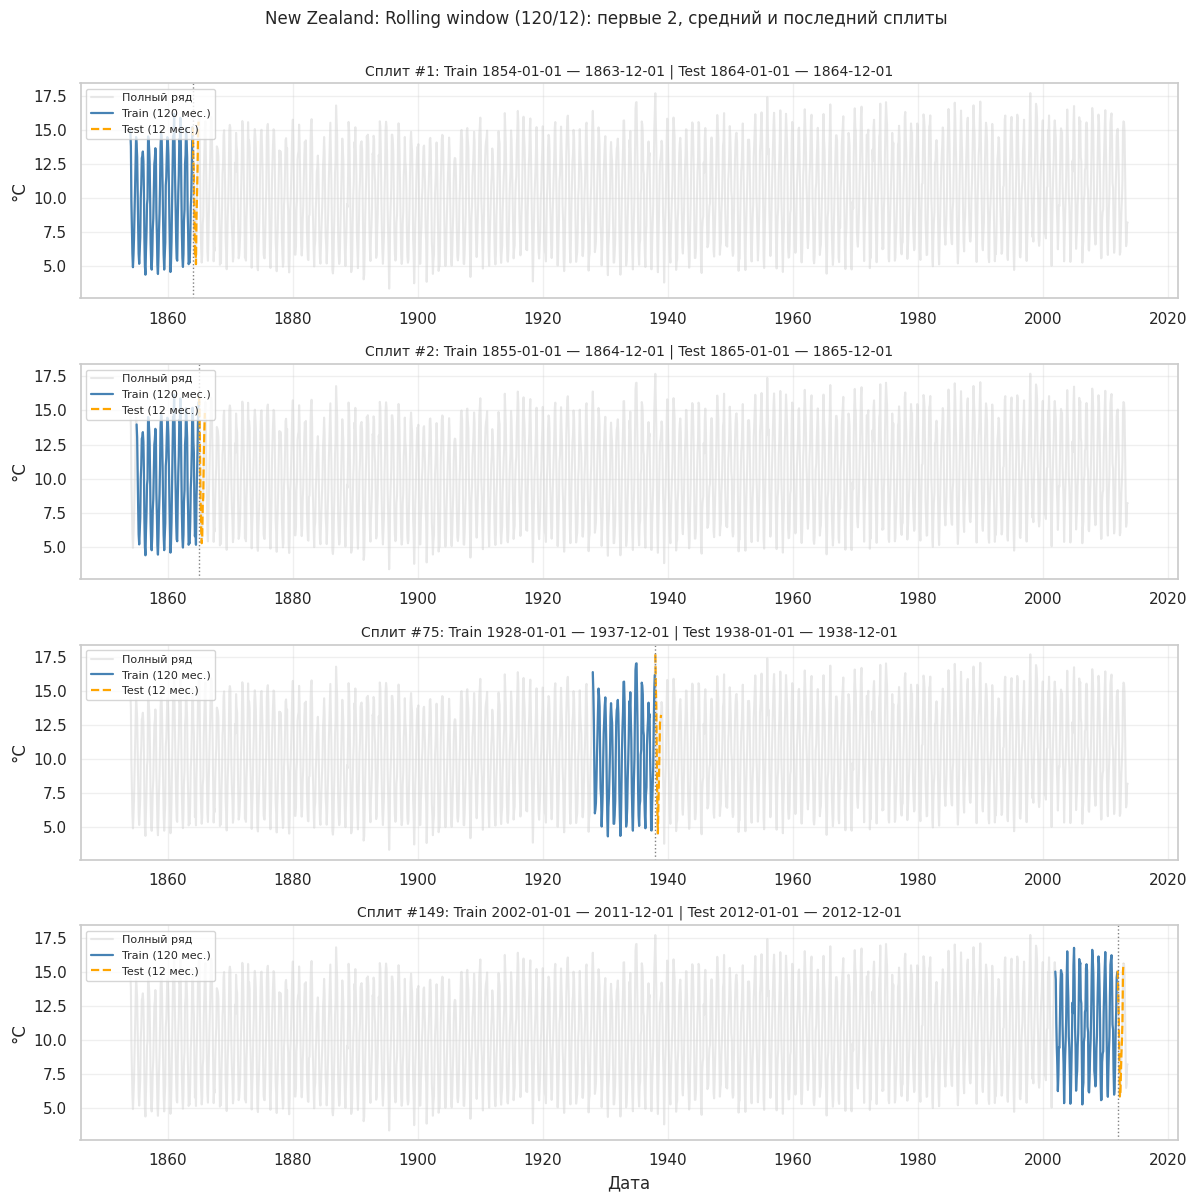

In [123]:
# Rolling window: 120 месяцев обучения, 12 месяцев прогноза
train_len = 120
horizon  = 12
step = horizon
splits = []
for start in range(0, len(fm_final) - train_len - horizon + 1, step):
    train_window = fm_final.iloc[start : start + train_len]
    test_window  = fm_final.iloc[start + train_len : start + train_len + horizon]
    splits.append((train_window, test_window))

print(f"Всего сгенерировано сплитов: {len(splits)}")
print(f"Первый: train {splits[0][0].index.min().date()} — {splits[0][0].index.max().date()} "
      f"| test {splits[0][1].index.min().date()} — {splits[0][1].index.max().date()}")
print(f"Последний: train {splits[-1][0].index.min().date()} — {splits[-1][0].index.max().date()} "
      f"| test {splits[-1][1].index.min().date()} — {splits[-1][1].index.max().date()}")
print('\n')


#4 сплита: первый, второй, средний и последний
idx_to_show = [0, 1, len(splits) // 2, len(splits) - 1]
n_show = len(idx_to_show)
fig, axes = plt.subplots(n_show, 1, figsize=(12, 3 * n_show), sharex=False)
for ax, idx in zip(axes, idx_to_show):
    train_window, test_window = splits[idx]
    ax.plot(fm_final.index, fm_final["y_target"],
            color="lightgray", alpha=0.5, label="Полный ряд")
    ax.plot(train_window.index, train_window["y_target"],
            color="steelblue", linewidth=1.6, label="Train (120 мес.)")
    ax.plot(test_window.index, test_window["y_target"],
            color="orange", linewidth=1.6, linestyle="--", label="Test (12 мес.)")
    ax.axvline(test_window.index[0], color="gray", linestyle=":", linewidth=1)

    ax.set_title(
        f"Сплит #{idx + 1}: "
        f"Train {train_window.index[0].date()} — {train_window.index[-1].date()} | "
        f"Test {test_window.index[0].date()} — {test_window.index[-1].date()}",
        fontsize=10)
    ax.set_ylabel("°C")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Дата")
plt.suptitle(f"{COUNTRY}: Rolling window (120/12): первые 2, средний и последний сплиты",
             fontsize=12, y=1.00)
plt.tight_layout()
plt.show()

## 5. Обучение модели

In [124]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

coefs = pd.Series(model.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)
print("Коэффициенты LinearRegression:")
print(coefs.round(3))
print(f"\nСвободный член: {model.intercept_:.3f}")

Коэффициенты LinearRegression:
month_cos         4.310
is_cold_season    0.915
roll_mean_12      0.443
month_sin        -0.202
lag_12            0.139
lag_1             0.121
dtype: float64

Свободный член: 2.816


In [125]:
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"{COUNTRY}: Метрики")
print(f"  MAE  = {mae:.3f}")
print(f"  RMSE = {rmse:.3f}")
print(f"  MAPE = {mape:.2f} %")

New Zealand: Метрики
  MAE  = 0.656
  RMSE = 0.818
  MAPE = 6.66 %


In [126]:
#сравнение с бейслайн
y_pred_persist = test["lag_1"]
mae_p  = mean_absolute_error(y_test, y_pred_persist)
rmse_p = np.sqrt(mean_squared_error(y_test, y_pred_persist))
mape_p = np.mean(np.abs((y_test - y_pred_persist) / y_test)) * 100

print("Сравнение с baseline (persistence):")
print(f" MAE  persistence = {mae_p:.3f}")
print(f" RMSE  persistence = {rmse_p:.3f}")
print(f" MAPE {mape_p:.2f}%")

Сравнение с baseline (persistence):
 MAE  persistence = 3.167
 RMSE  persistence = 3.525
 MAPE 33.08%


Модель справляется лучше, чем бейслайн persistence и  уверенно ловит сезонность. Основными вкладчиками в результат предсказания стали сезонные фичи (month_cos 4.310 и is_cold_season 0.915), интересно, что модель не сильно опирается на показания температуры год назад и прошлого месяца (lag_12 0.139 и
lag_1 0.121). MAE 0.66 градуса для климатического ряда с разбросом температуры в 5 градусов очень хороший результат. RMSE 0.8 градуса - чуть выше МАЕ, значит крупных выбросов  в ошибках нет. MAPE 6.7% надежная метрика, именно для Новой Зеландии, т.к. y_test далек от 0 даже зимой и знаменатель не раздувает MAPE. Для других регионов возможно понадобиться корректировка показателя с учетом перехода нулевой температуры